In [1]:
!pip install hdbscan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [3]:
# Mengambil dataset Iris
iris = load_iris()

X = iris.data
y = iris.target

# Membuat DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)

print("Lima data pertama:")
print(df.head())

print("\nUkuran dataset:", df.shape)

print("\nJumlah label asli:")
print(pd.Series(y).value_counts().sort_index())

Lima data pertama:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Ukuran dataset: (150, 4)

Jumlah label asli:
0    50
1    50
2    50
Name: count, dtype: int64


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Hasil normalisasi:")
print(X_scaled[:5])

Hasil normalisasi:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [5]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

cluster_labels = clusterer.fit_predict(X_scaled)

print("Hasil clustering:")
print(cluster_labels[:20])

Hasil clustering:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [6]:
# Menghitung jumlah cluster tanpa noise
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)

# Menghitung jumlah noise
n_noise = np.sum(cluster_labels == -1)

# Menghitung persentase noise
noise_percentage = (n_noise / len(X)) * 100

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)
print("Persentase noise:", round(noise_percentage, 2), "%")

Jumlah cluster: 2
Jumlah noise: 2
Persentase noise: 1.33 %


In [7]:
unique_labels, counts = np.unique(
    cluster_labels,
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    if label == -1:
        print(f"Noise: {count} data")
    else:
        print(f"Cluster {label}: {count} data")

Noise: 2 data
Cluster 0: 99 data
Cluster 1: 49 data


In [8]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Ukuran data setelah PCA:", X_pca.shape)

Ukuran data setelah PCA: (150, 2)


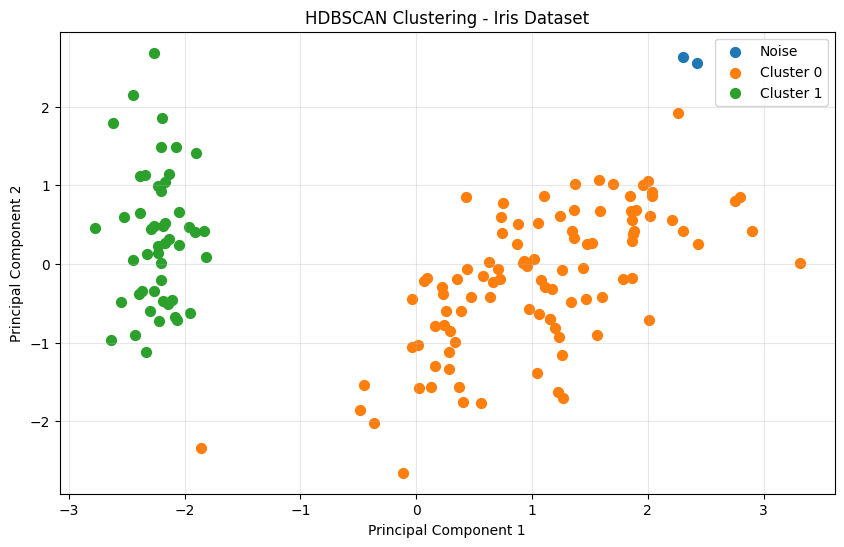

In [9]:
plt.figure(figsize=(10, 6))

for label in np.unique(cluster_labels):

    mask = cluster_labels == label

    if label == -1:
        nama = "Noise"
    else:
        nama = f"Cluster {label}"

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=nama,
        s=50
    )

plt.title("HDBSCAN Clustering - Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

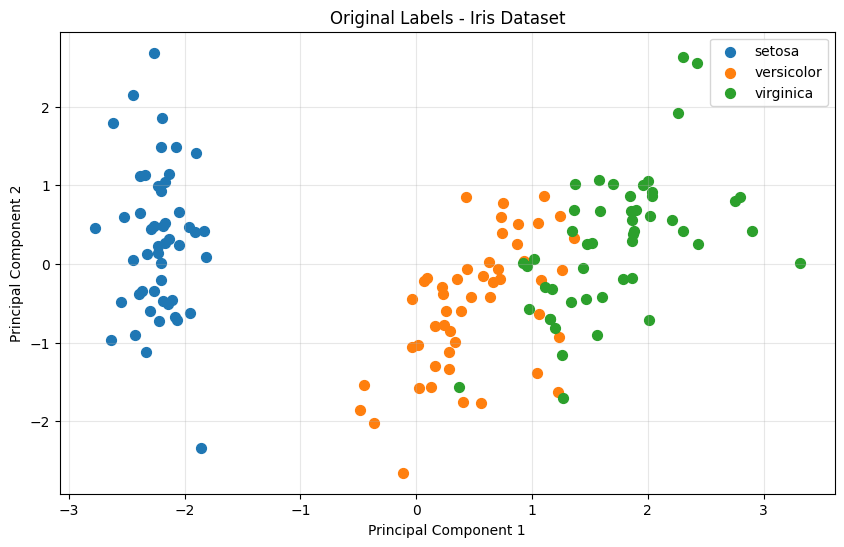

In [10]:
plt.figure(figsize=(10, 6))

for label in np.unique(y):

    mask = y == label

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=iris.target_names[label],
        s=50
    )

plt.title("Original Labels - Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
comparison = pd.crosstab(
    pd.Series(y, name="Original Label"),
    pd.Series(cluster_labels, name="HDBSCAN Cluster")
)

print(comparison)

HDBSCAN Cluster  -1   0   1
Original Label             
0                 0   1  49
1                 0  50   0
2                 2  48   0


In [12]:
ari = adjusted_rand_score(y, cluster_labels)

print("Adjusted Rand Index:", round(ari, 4))

Adjusted Rand Index: 0.5394
